# 03 · Preprocessing (Member A)

Cleans the LBNL chiller plant data and adds the team's derived metrics.
**Every file gets exactly the same steps** (settings in `config.yaml` → `preprocess:`):

1. Frozen-sensor removal (60 min unchanged while running; hourly weather excluded)
2. No 3-sigma removal (`outlier_removal: false`): the data are simulated, so there are no sensor errors, and on fault files the test would delete the fault itself
3. 15-minute means
4. Keep only windows where at least one chiller is on
5. Derived metrics: `CHL_DT_i`, `CHL_COOL_i`, `CHL_COP_i`, `CHL_CDDT_i`, `CT_APPROACH_i`, `PLANT_POW`, `PLANT_COP`

**What this notebook shows:** rows before and after cleaning · hours with chillers on per month · histograms of `CHL_COP_1` and `PLANT_COP` · an energy-balance check of the cooling formula.

Set `DATA_DIR` in your `.env` to the folder with the 24 CSV files.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":          # run from the repo root
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from src import preprocess as pp

S = pp.load_settings("config.yaml")
pd.set_option("display.width", 140)
{k: S[k] for k in ["frozen_removal", "frozen_window", "outlier_removal", "resample",
                   "min_coverage", "chiller_on_only", "min_cool_kw", "delta_t_scale"]}

{'frozen_removal': True,
 'frozen_window': 60,
 'outlier_removal': False,
 'resample': '15min',
 'min_coverage': 0.67,
 'chiller_on_only': True,
 'min_cool_kw': 50,
 'delta_t_scale': 1.0}

## Pick the files
The fault-free year and one fault file, processed with the same steps.

In [2]:
files = pp.list_files(pp.data_dir(S["raw_dir"]))
FAULT_FREE = pp.find_fault_free(files, S["fault_free_file"])      # ChillerPlant.csv
FAULT_FILE = next((f for f in files if "coolingtower_fouling" in f.name),
                  next(f for f in files if f != FAULT_FREE))      # change to any scenario
LIMITS = pp.fit_limits(pp.load_csv(FAULT_FREE), S) if S["outlier_removal"] else None
print(len(files), "CSV files found")
print("fault-free :", FAULT_FREE.name)
print("example    :", FAULT_FILE.name)
print("3-sigma step:", "ON (all files)" if S["outlier_removal"] else "OFF (all files)")

24 CSV files found
fault-free : ChillerPlant.csv
example    : ChillerPlant_coolingtower_fouling_065.csv
3-sigma step: OFF (all files)


## 1 · Rows before and after cleaning

In [3]:
results = {}
for f in [FAULT_FREE, FAULT_FILE]:
    raw, full, rep, saved = pp.process_file(f, LIMITS, S)
    results[f.name] = (raw, full, rep)
    print("saved", saved)

summary = pd.DataFrame({
    name: {
        "raw 1-min rows": r["rows_raw"],
        "after frozen-sensor removal": r["rows_after_frozen"],
        "after 3-sigma removal": r["rows_after_outliers"],
        "15-min windows": r["rows_15min"],
        "windows with a chiller on": r["rows_chiller_on"],
        "% of 1-min rows kept before resampling": round(100 * r["rows_after_outliers"] / r["rows_raw"], 2),
    } for name, (_, _, r) in results.items()
}).T
summary

saved data\processed\ChillerPlant.parquet
saved data\processed\ChillerPlant_coolingtower_fouling_065.parquet


,raw 1-min rows,after frozen-sensor removal,after 3-sigma removal,15-min windows,windows with a chiller on,% of 1-min rows kept before resampling
ChillerPlant.csv,525540.0,495947.0,495947.0,32978.0,32978.0,94.37
ChillerPlant_coolingtower_fouling_065.csv,525540.0,495555.0,495555.0,32950.0,32950.0,94.29


In [4]:
# Which sensors caused the frozen-sensor removals (same rule for both files)
for name, (_, _, r) in results.items():
    print(f"=== {name}")
    fz = r.get("frozen_by_column", pd.Series(dtype=int))
    print("frozen, top columns:\n", fz.head(8).to_string() if len(fz) else "  none")
    if r.get("frozen_check_skipped"):
        print("frozen check skipped (constant by design, e.g. fixed-speed pumps):",
              sorted(r["frozen_check_skipped"]))
    print()

=== ChillerPlant.csv
frozen, top columns:
 CHL_POW_1          28833
CDWL_SW_TEMP        1231
CT_RW_TEMP_1        1193
CDWL_RW_TEMP        1192
CHL_RWCD_TEMP_1     1123
CHL_SWCD_TEMP_1      901
CT_POW_2             643
CT_SW_TEMP_1         487
frozen check skipped (constant by design, e.g. fixed-speed pumps): ['CDWL_CW_FLOW', 'CDWL_PM_POW_1', 'CDWL_PM_POW_2', 'CDWL_PM_POW_3', 'CHL_CD_FLOW_1', 'CHL_CD_FLOW_2', 'CHL_CD_FLOW_3', 'CHL_CW_FLOW_1', 'CHL_CW_FLOW_2', 'CHL_CW_FLOW_3', 'CHL_RW_TEMP_1', 'CHL_SW_TEMP_1', 'CT_FLOW_1', 'CT_FLOW_2', 'CT_FLOW_3', 'CT_POW_1', 'CWL_PRI_CW_FLOW', 'CWL_PRI_PM_POW_1', 'CWL_PRI_PM_POW_2', 'CWL_PRI_PM_POW_3', 'CWL_PRI_RW_TEMP', 'CWL_PRI_SW_TEMP', 'CWL_SEC_CW_FLOW', 'CWL_SEC_DP', 'CWL_SEC_LOAD', 'CWL_SEC_PM_POW_1', 'CWL_SEC_PM_POW_2', 'CWL_SEC_RW_TEMP', 'CWL_SEC_SW_TEMP']

=== ChillerPlant_coolingtower_fouling_065.csv
frozen, top columns:
 CHL_POW_1          27524
CT_POW_2            2397
CHL_SWCD_TEMP_1     1161
CDWL_RW_TEMP        1122
CT_RW_TEMP_1        11

## 2 · Hours with chillers on, per month
From the raw 1-minute fault-free year.

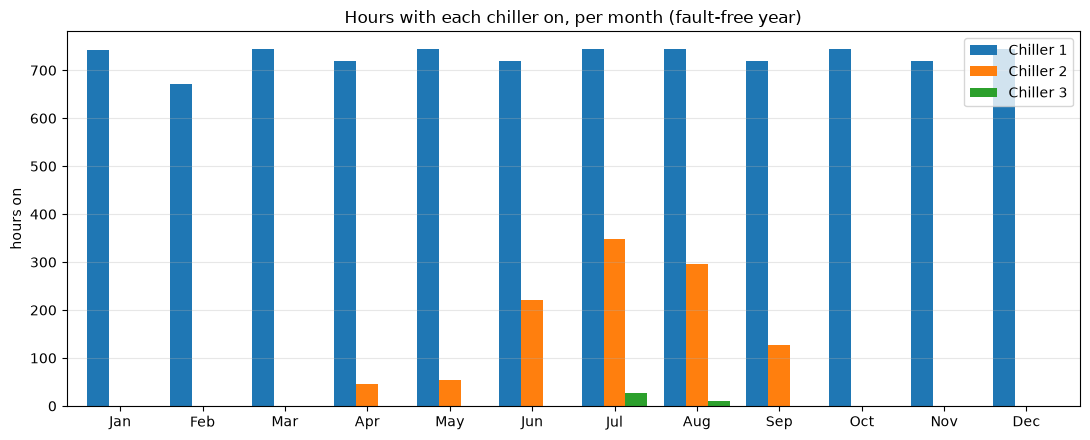

Total hours on: {'Chiller 1': 8759.0, 'Chiller 2': 1089.7, 'Chiller 3': 38.2}


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Chiller 1,743.0,672.0,744.0,720.0,744.0,720.0,744.0,744.0,720.0,744.0,720.0,744.0
Chiller 2,0.0,0.0,0.0,45.0,54.7,220.6,347.4,295.0,127.0,0.0,0.0,0.0
Chiller 3,0.0,0.0,0.0,0.0,0.8,0.6,26.6,9.3,0.9,0.0,0.0,0.0


In [5]:
ff_raw = results[FAULT_FREE.name][0]
sta = ff_raw[[f"CHL_STA_{i}" for i in range(1, S["n_chillers"] + 1)]] > 0.5
hours = sta.groupby(sta.index.month).sum() / 60          # 1-minute data -> hours
hours.index = [pd.Timestamp(2018, m, 1).strftime("%b") for m in hours.index]
hours.columns = [f"Chiller {i}" for i in range(1, S["n_chillers"] + 1)]

ax = hours.plot.bar(figsize=(11, 4.5), width=0.8)
ax.set_ylabel("hours on"); ax.set_xlabel("")
ax.set_title("Hours with each chiller on, per month (fault-free year)")
ax.grid(axis="y", alpha=.3); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Total hours on:", hours.sum().round(1).to_dict())
hours.round(1).T

## Energy-balance check of the cooling formula
`CHL_COOL_i = flow (GPM) × ΔT (°F) × 500 / 3412.14` (kW). The cooling made by the chillers should roughly equal the building load `CWL_SEC_LOAD / 1000` (kW), so the ratio below should be close to 1. A ratio near 0.56 would mean the temperatures are in °C (set `delta_t_scale: 1.8`).

count    9299.000
mean        0.990
std         0.215
min         0.041
25%         0.944
50%         1.017
75%         1.079
max         3.936


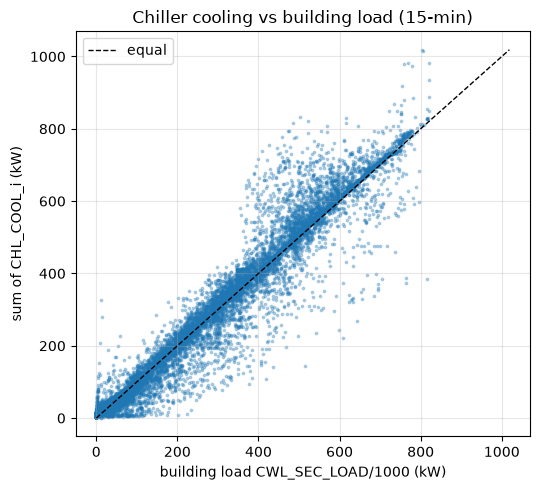

In [6]:
ff = results[FAULT_FREE.name][1]
ratio = pp.energy_balance(ff, S)
print(ratio.round(3).to_string())
cool = sum(ff[f"CHL_COOL_{i}"] for i in range(1, S["n_chillers"] + 1))
load = ff["CWL_SEC_LOAD"] / 1000
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(load, cool, s=3, alpha=.3)
m = float(max(load.max(), cool.max()))
ax.plot([0, m], [0, m], "k--", lw=1, label="equal")
ax.set_xlabel("building load CWL_SEC_LOAD/1000 (kW)"); ax.set_ylabel("sum of CHL_COOL_i (kW)")
ax.set_title("Chiller cooling vs building load (15-min)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3 · COP histograms
Only windows with real cooling (≥ `min_cool_kw`). A healthy chiller is roughly 4–6; plant COP is lower because pumps and fans are included.

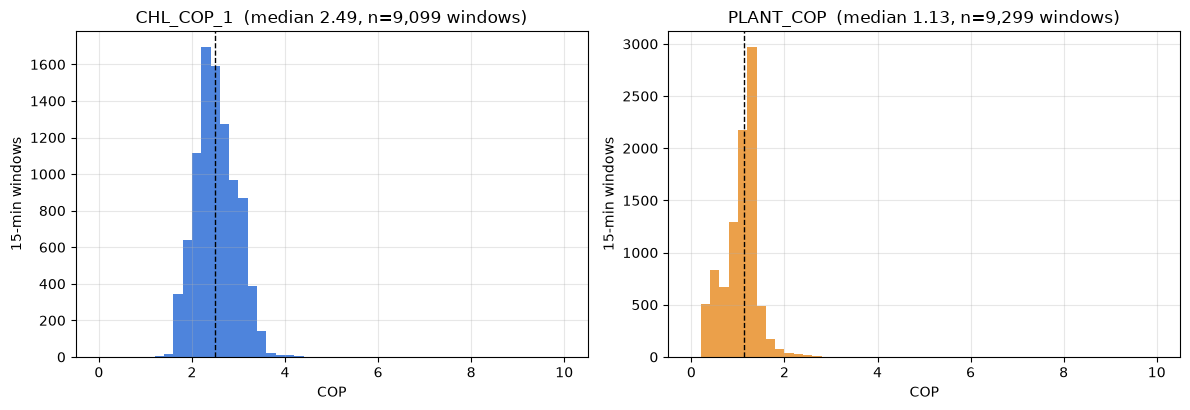

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, colr in zip(axes, ["CHL_COP_1", "PLANT_COP"], ["#2f6fd6", "#e8902a"]):
    x = ff[col].dropna()
    ax.hist(x.clip(0, 10), bins=50, range=(0, 10), color=colr, alpha=.85)
    ax.axvline(x.median(), color="k", ls="--", lw=1)
    ax.set_title(f"{col}  (median {x.median():.2f}, n={len(x):,} windows)")
    ax.set_xlabel("COP"); ax.set_ylabel("15-min windows"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Derived columns
Names agreed with the team (Member B uses them as graph nodes).

In [8]:
derived = [c for c in ff.columns
           if c.startswith(("CHL_DT_", "CHL_COOL_", "CHL_COP_", "CHL_CDDT_", "CT_APPROACH_"))
           or c in ("PLANT_POW", "PLANT_COP")]
print("negative CT_APPROACH values:",
      {c: int((ff[c] < 0).sum()) for c in derived if c.startswith("CT_APPROACH_")})
ff[derived].describe().T.round(2)

negative CT_APPROACH values: {'CT_APPROACH_1': 5298, 'CT_APPROACH_2': 2565, 'CT_APPROACH_3': 89}


,count,mean,std,min,25%,50%,75%,max
CHL_DT_1,32978.0,1.70,2.81,0.02,0.10,0.10,2.03,11.68
CHL_COOL_1,32978.0,69.76,115.11,0.63,4.28,4.28,82.89,478.26
CHL_COP_1,9099.0,2.53,0.45,1.06,2.22,2.49,2.83,9.45
CHL_CDDT_1,32978.0,1.66,2.74,-0.19,0.10,0.10,1.99,11.15
CHL_DT_2,4314.0,6.54,1.61,0.10,5.74,6.63,7.61,10.66
CHL_COOL_2,32978.0,34.89,93.08,0.00,0.00,0.00,0.00,436.26
CHL_COP_2,4217.0,2.29,0.31,1.40,2.09,2.30,2.50,4.84
CHL_CDDT_2,4314.0,6.42,1.56,0.41,5.55,6.49,7.47,10.71
CHL_DT_3,156.0,6.01,0.78,3.12,5.62,6.09,6.30,9.04
CHL_COOL_3,32978.0,1.12,16.42,0.00,0.00,0.00,0.00,355.31


## Process all 24 files
Same steps for every file; output in `data/processed/`. Takes a while. Same as running `python -m src.preprocess`.

In [9]:
RUN_ALL = False
if RUN_ALL:
    table = pp.process_all(S)
    table